In [22]:
from anemone.transforms import *
import matplotlib.pyplot as plt
import numpy as np

import torch

In [86]:
class Fourier(Hankel):
    """ A fourier transform for logarithmically sampled data. The implementation uses hankel transforms at the base.
        See Johansen and Sorensen 1979 - Fast Hankel Transforms eq.  87 + 88
    """
        
    def __init__(self, func, log10min=-20, log10max=10, smp_per_decade=16, device=None, range=None):
        def f1(lamda):
            return func(lamda/c.sqrt_twopi)/torch.sqrt(torch.abs(lamda))
        super().__init__(f1, -0.5, log10min, log10max, smp_per_decade, device, None, )
        self.lambda_included = False
        _, realfc = hankel_coefficients(-0.5, log10min, log10max, smp_per_decade, omega_0=0.6221)
        _, imagfc = hankel_coefficients( 0.5, log10min, log10max, smp_per_decade, omega_0=0.6221)
        imagfc = imagfc.to(self.fc.device)
        self.fc = torch.complex(realfc, -1*imagfc)
       

        if range is not None:
            self._recenter_function(range)
            self.create_interpolator(range[0], range[1])
    

    def _range(self, rmin, rmax, negatives=False):
        """
        Compute the range of values between `rmin` and `rmax`.

        Parameters:
        - rmin (float): The minimum value of the range.
        - rmax (float): The maximum value of the range.

        Returns:
        - rout (torch.Tensor): The range of values between `rmin` and `rmax`.
        - HR (torch.Tensor): The computed values based on the range.

        """
        if self.func_results is None:
            self.func_results = self.func(self.lamda)
            if not self.lambda_included: 
                self.func_results *= self.lamda


        if not isinstance(rmin, torch.Tensor): rmin = torch.tensor(rmin, device=self.device)
        if not isinstance(rmax, torch.Tensor): rmax = torch.tensor(rmax, device=self.device)
        imin = int(torch.floor(self.r_to_idx(rmin)))-2
        imax = int(torch.ceil(self.r_to_idx(rmax)))+2
        i_offsets = torch.arange(imin, imax, device=self.device)
        rout = self.idx_to_r(i_offsets).to(self.lamda.dtype)
        HR = torch.zeros(self.func_results.shape[:-1] + rout.shape, dtype=self.func_results.dtype, device=self.device)
        HR = torch.zeros(self.func_results.shape[:-1] + rout.shape, dtype=self.func_results.dtype, device=self.device)
        if self.device is not None:
            rout = rout.to(self.device)
            HR = HR.to(self.device)
            i_offsets = i_offsets.to(self.device)
        if self.fc.dtype != self.func_results.dtype:
            self.fc = self.fc.to(self.func_results.dtype)


        for i, i_offset in enumerate(i_offsets):
            if i_offset == 0:
                HR[..., i] = torch.einsum('...i,...i->...', self.func_results, self.fc)
            elif i_offset > 0:
                HR[..., i] = torch.einsum('...i,...i->...', self.func_results[..., :-i_offset], self.fc[..., i_offset:])
            else:
                i_offset *= -1
                HR[..., i] = torch.einsum('...i,...i->...', self.fc[..., :-i_offset], self.func_results[..., i_offset:])
        HR = HR/rout

        if negatives:
            self.neg_func_results = self.func(-self.lamda)
            # print('negative lambda', -self.lamda)
            # print('neg func results', self.neg_func_results)
            if not self.lambda_included: 
                self.neg_func_results *= -self.lamda            

            HRn = torch.zeros(self.func_results.shape[:-1] + rout.shape, dtype=self.func_results.dtype, device=self.device)
            if self.device is not None:
                HRn = HRn.to(self.device)

            for i, i_offset in enumerate(i_offsets):
                if i_offset == 0:
                    HRn[..., i] = torch.einsum('...i,...i->...', self.neg_func_results, self.fc)
                elif i_offset > 0:
                    HRn[..., i] = torch.einsum('...i,...i->...', self.neg_func_results[..., :-i_offset], self.fc[..., i_offset:])
                else:
                    i_offset *= -1
                    HRn[..., i] = torch.einsum('...i,...i->...', self.fc[..., :-i_offset], self.neg_func_results[..., i_offset:])
            HRn = -HRn/rout
            HR = torch.concat([torch.flip(HRn, dims=[-1]), HR], dim=-1)
            rout = torch.concat([-1*torch.flip(rout, [0]), rout])
        return rout, torch.nan_to_num(HR)


    def f2r(self, f):
        """frequency to r"""
        return f*c.sqrt_twopi
    
    def r2f(self, r):
        """r to frequency"""
        return r/c.sqrt_twopi

    def range(self, fmin, fmax, negatives=False):
        rout, Resp = self._range(self.f2r(fmin), self.f2r(fmax), negatives=negatives)
        return self.r2f(rout), Resp*torch.sqrt(torch.abs(rout))
    
    def __call__(self, r):
        if isinstance(r, float): r = torch.tensor(r, device=self.device)
        rmax = r.max()
        rmin = torch.abs(r).min()

        if not 'interpfunc' in dir(self):
            negatives = torch.any(r < 0)
            self.r, self.resp = self.range(rmin, rmax, negatives=negatives)
            if not negatives:
                self.interpfunc = CubicSpline(self.r, self.resp, integrate=False, transform=torch.log10)
            else:
                self.interpfunc = CubicSpline(self.r, self.resp, integrate=False)
        r = r if isinstance(r, torch.Tensor) else torch.tensor(r, device=self.device)
        return self.interpfunc(r)


class invFourier(Fourier):
    def __init__(self, func, log10min=-20, log10max=10, smp_per_decade=20, device=None, range=None):
        super().__init__(func, log10min, log10max, smp_per_decade, device, None)
        self.lambda_included = False        
        self.fc = self.fc.real - 1j*self.fc.imag
        if range is not None:
            self._recenter_function(range)
            self.create_interpolator(range[0], range[1])
    def __repr__(self) -> str:
        return 'X(f)->x(t)'

In [ ]:
def func(f):
    return 1./(1j*torch.pi)

In [94]:
t = torch.linspace(-1e3, 1e3, 1000)


#t = torch.logspace(-6, 6, 1000)


F = invFourier(func)
tout,f = F.range(1.e-6, 1., negatives=True)

In [95]:
f[torch.abs(f.real)>10.]  = 0.

In [96]:
f

tensor([-0.5000+14.1635j, -0.5000+14.2001j, -0.5000+14.2368j, -0.5000+14.2734j,
        -0.5000+14.3101j, -0.5000+14.3467j, -0.5000+14.3834j, -0.5000+14.4200j,
        -0.5000+14.4567j, -0.5000+14.4933j, -0.5610+16.2206j, -0.6295+18.1537j,
        -0.7063+20.3170j, -0.7924+22.7380j, -0.8891+25.4473j, -0.9976+28.4792j,
        -1.1194+31.8722j, -1.2559+35.6691j, -1.4092+39.9181j, -1.5811+44.6730j,
        -1.7741+49.9939j, -1.9905+55.9481j, -2.2334+62.6112j, -2.5059+70.0672j,
        -2.8117+78.4106j, -3.1548+87.7469j, -3.5397+98.1942j, -3.9716+109.8847j,
        -4.4563+122.9660j, -5.0000+137.6037j, -5.6101+153.9827j, -6.2946+172.3100j,
        -7.0627+192.8174j, -7.9245+215.7639j, -8.8914+241.4393j, -9.9763+270.1682j,
         0.0000+0.0000j,  0.0000+0.0000j,  0.0000+0.0000j,  0.0000+0.0000j,
         0.0000+0.0000j,  0.0000+0.0000j,  0.0000+0.0000j,  0.0000+0.0000j,
         0.0000+0.0000j,  0.0000+0.0000j,  0.0000+0.0000j,  0.0000+0.0000j,
         0.0000+0.0000j,  0.0000+0.0000j,  

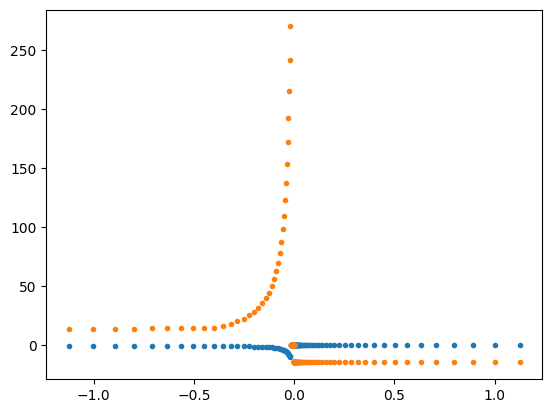

In [98]:
plt.plot(tout, f.real, '.', label='Real')
plt.plot(tout, f.imag, '.', label='Real')
# plt.plot(t, torch.ones_like(t)*0.5)

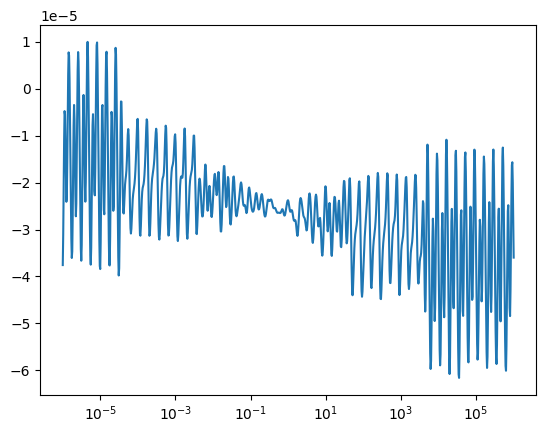

In [21]:
plt.figure()
plt.semilogx(t, 100*(f.real-0.5)/0.5)